In [10]:
%%writefile src/buat_dataset_sintetis.py
import os
import csv
import cv2
import numpy as np

SEED = 1008
N_PER_KELAS = 20
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")
rng = np.random.default_rng(SEED)

def gambar_daun(img, mask):
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150), rng.integers(45, 75)])
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask

def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)), int(rng.integers(185, 210))]
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak[:] = mask_bercak & mask_daun

def ganggu_cahaya(img, kondisi):
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = f * 0.35 + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)
    return np.clip(f, 0, 255).astype(np.uint8)

def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205), rng.integers(185, 215)])
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")

if __name__ == "__main__":
    main()

Writing src/buat_dataset_sintetis.py


In [11]:
!python src/buat_dataset_sintetis.py

Selesai: 60 citra tersimpan di data/sintetis


In [12]:
%%writefile src/praproses.py
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

def praproses(img_bgr, p=None):
    p = {**PARAM_BAWAAN, **(p or {})}
    h, w = img_bgr.shape[:2]
    lebar_baru = p["lebar"]
    tinggi_baru = int(h * lebar_baru / w)
    img = cv2.resize(img_bgr, (lebar_baru, tinggi_baru), interpolation=cv2.INTER_AREA)

    if p["gamma"] != 1.0:
        inv_gamma = 1.0 / p["gamma"]
        table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in range(256)]).astype("uint8")
        img = cv2.LUT(img, table)

    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    penapis = p["penapis"]
    k = p["kernel"]
    if penapis == "rerata":
        img = cv2.blur(img, (k, k))
    elif penapis == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif penapis == "median":
        img = cv2.medianBlur(img, k)

    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1.0 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img

def simpan_param(p, path="hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing src/praproses.py


OpenCV 4.14.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 250
piksel (y=100, x=200) dalam urutan BGR: [171 190 204]


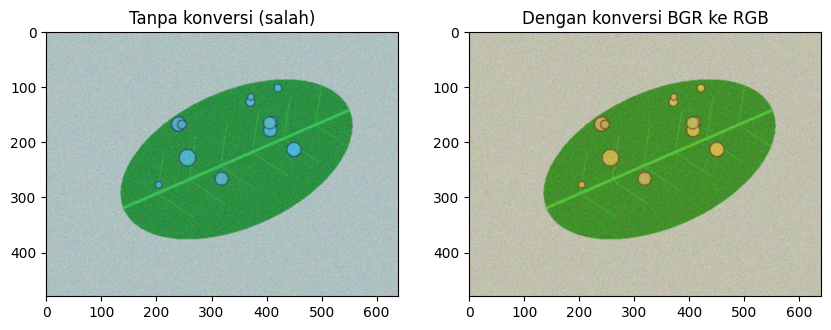

In [14]:
import os
import sys

# Posisikan direktori kerja otomatis ke root folder utama (simuteh-1008)
if os.getcwd().endswith("notebook"):
    os.chdir("..")

sys.path.append("src")
import cv2
import numpy as np
import skimage
import matplotlib.pyplot as plt
from utils_cv import baca, tampil

print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| scikit-image", skimage.__version__)

# Membaca citra uji pertama
img = baca("data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])

# Menampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.savefig("hasil/b1_bgr_rgb.png")
plt.show()